<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH5_%E9%96%BE%E5%80%BC%E8%99%95%E7%90%86.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 閾值處理與二值化 (Thresholding)

## 1.閾值基本概念與 cv2.threshold
- Thresh `門檻, 閾`
> threshold 是`門檻值`的意思，OpenCV 提供的 threshold 工具包裡面有影像門檻值的功能，當畫素值高於門檻值時，我們給這個畫素賦予一個新值（可能是白色），否則我們給它賦予另一種顏色（也許是黑色）。這個函式就是 cv2.threshold()

> 影像的二值化就是將影像上的像素點的`灰度值`設置為 0 或 255，這樣將使整個影像呈現出明顯的黑白效果。在數位影像處理中，二值影像佔有非常重要的地位，影像的二值化使影像中資料量大為減少，從而能凸顯出`目標的輪廓`。

### 遮罩技術 (Masking & ROI Extraction)

影像定義域為像素格點：

$
\Omega = \{(x,y) \mid 0 \le x < W,\; 0 \le y < H\}
$

遮罩選出其中一個子集 $M \subseteq \Omega$：

$
M = \{(x,y) \in \Omega \mid \mathrm{mask}(x,y) = 255\}
$

指示函數（indicator function）形式：

$
\mathbb{1}_M(x,y) =
\begin{cases}
1, & (x,y) \in M \\[4pt]
0, & (x,y) \notin M
\end{cases}
$

$
\mathrm{mask}(x,y) = 255 \cdot \mathbb{1}_M(x,y)
$

### 遮罩概念：0 與 255 的幾何意義





mode        : THRESH_BINARY
img  shape  : (371, 538)   dtype: uint8
dst  shape  : (371, 538)   dtype: uint8
ret         : 127.0         (實際套用的閾值)
值域        : 0 ~ 255
白色 (255)  :    40724 px  (20.40%)
黑色 (0)    :   158874 px  (79.60%)
相異值      : {0: 158874, 255: 40724}

ROI slice   : [179:191, 261:277]  shape = (12, 16)

roi_img（灰階 0-255）：
[[217 227 237 248 249 249 246 242 238 237 237 232 231 230 229 226]
 [221 232 240 245 246 246 243 237 232 230 229 223 221 219 216 212]
 [230 239 245 243 243 242 237 229 221 217 215 213 210 206 202 199]
 [233 242 249 247 247 243 235 224 213 206 202 195 193 190 189 191]
 [231 240 250 254 253 248 238 224 211 201 197 179 177 177 181 189]
 [239 247 249 250 249 244 233 219 207 201 199 192 189 186 186 191]
 [250 251 248 246 244 239 228 214 202 195 192 200 200 202 205 209]
 [255 254 250 247 245 238 227 214 203 196 193 201 205 210 215 218]
 [253 253 252 253 248 238 227 216 208 204 203 201 203 206 210 213]
 [251 249 246 250 242 231 221 213 210 210 210 203 201 19

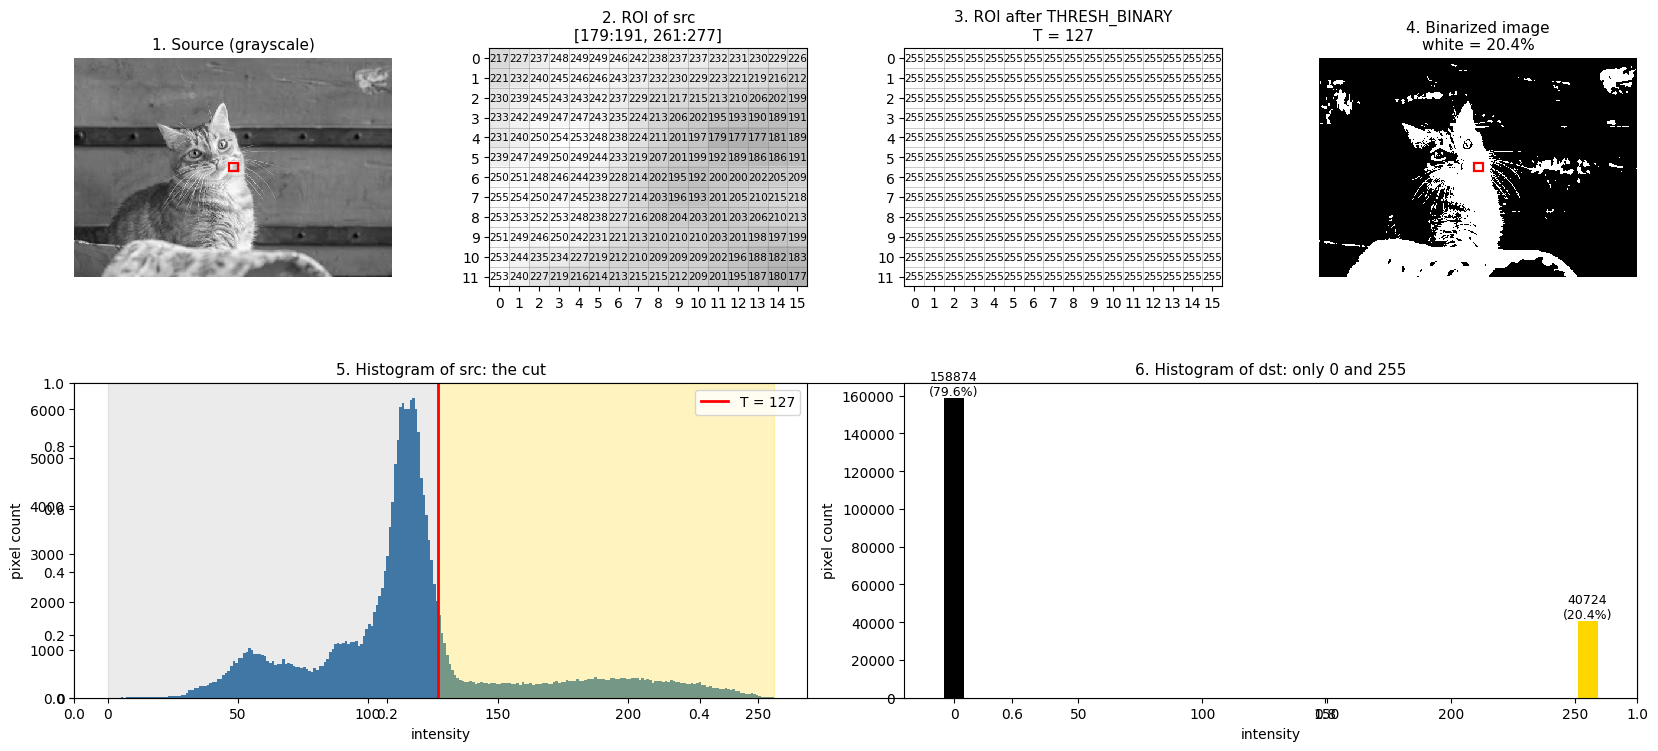

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------- 參數 ----------------
PATH   = "images.jpg"
THRESH = 127
MAXVAL = 255
ROI_H  = 12            # ROI 列數
ROI_W  = 16            # ROI 行數

# ---------------- 讀圖 + 二值化 ----------------
img = cv2.imread(PATH, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"讀不到影像：{PATH}")

ret, dst = cv2.threshold(img, THRESH, MAXVAL, cv2.THRESH_BINARY)

# ================= 1. dst 資訊 =================
h, w  = dst.shape[:2]
white = int(np.count_nonzero(dst))
total = int(dst.size)

print("=" * 56)
print(f"mode        : THRESH_BINARY")
print(f"img  shape  : {img.shape}   dtype: {img.dtype}")
print(f"dst  shape  : {dst.shape}   dtype: {dst.dtype}")
print(f"ret         : {ret}         (實際套用的閾值)")
print(f"值域        : {dst.min()} ~ {dst.max()}")
print(f"白色 (255)  : {white:>8d} px  ({white / total:6.2%})")
print(f"黑色 (0)    : {total - white:>8d} px  ({(total - white) / total:6.2%})")
print("=" * 56)

# ================= 2. dst 的值 =================
vals, counts = np.unique(dst, return_counts=True)
print("相異值      :", dict(zip(vals.tolist(), counts.tolist())))

# 切出中央 ROI（夾在合法範圍，避免小圖越界）
r0 = max(0, min(h // 2 - ROI_H // 2, h - ROI_H))
c0 = max(0, min(w // 2 - ROI_W // 2, w - ROI_W))
roi_img = img[r0:r0 + ROI_H, c0:c0 + ROI_W]
roi_dst = dst[r0:r0 + ROI_H, c0:c0 + ROI_W]

np.set_printoptions(linewidth=200, threshold=10000)
print(f"\nROI slice   : [{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]  shape = {roi_dst.shape}")
print(f"\nroi_img（灰階 0-255）：\n{roi_img}")
print(f"\nroi_dst（只有 0 / 255）：\n{roi_dst}")
print(f"\nROI 白色占比: {np.count_nonzero(roi_dst) / roi_dst.size:.1%}\n")

# ================= 3. matplotlib 顯示 =================
fig = plt.figure(figsize=(17, 8.4))
gs  = fig.add_gridspec(2, 4, height_ratios=[1.35, 1])

# --- [1] 原圖 ---
ax = fig.add_subplot(gs[0, 0])
ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title("1. Source (grayscale)", fontsize=11)
ax.axis("off")

# --- [2] 原圖上的灰階 ROI ---
ax = fig.add_subplot(gs[0, 1])
ax.imshow(roi_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_img):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v <= THRESH else "black")     # 紅字 = 會被歸 0
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"2. ROI of src\n[{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]", fontsize=11)

# --- [3] 閾值後的 ROI ---
ax = fig.add_subplot(gs[0, 2])
ax.imshow(roi_dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_dst):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v == 0 else "black")
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"3. ROI after THRESH_BINARY\nT = {THRESH}", fontsize=11)

# --- [4] 全圖 ---
ax = fig.add_subplot(gs[0, 3])
ax.imshow(dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title(f"4. Binarized image\nwhite = {white/total:.1%}", fontsize=11)
ax.axis("off")

# ================= 4. 直方圖 =================
ax = fig.add_subplot(gs[1, :])

# 左半：src 直方圖（細一點，畫滿 256 bin）
ax_src = fig.add_subplot(gs[1, 0:2])
ax_src.hist(img.ravel(), bins=256, range=(0, 256), color="steelblue")
ax_src.axvline(THRESH, color="red", lw=2, label=f"T = {THRESH}")
ax_src.axvspan(0, THRESH, color="black", alpha=0.08)
ax_src.axvspan(THRESH, 256, color="gold", alpha=0.25)
ax_src.set_title("5. Histogram of src: the cut", fontsize=11)
ax_src.set_xlabel("intensity"); ax_src.set_ylabel("pixel count")
ax_src.legend()

# 右半：dst 直方圖（只有兩根柱）
ax_dst = fig.add_subplot(gs[1, 2:4])
ax_dst.bar(vals, counts, width=8,
           color=["black" if v == 0 else "gold" for v in vals])
for v, c in zip(vals, counts):
    ax_dst.text(v, c, f"{c}\n({c/total:.1%})", ha="center", va="bottom",
                fontsize=9)
ax_dst.set_xlim(-20, 275)
ax_dst.set_title("6. Histogram of dst: only 0 and 255", fontsize=11)
ax_dst.set_xlabel("intensity"); ax_dst.set_ylabel("pixel count")

plt.tight_layout()
plt.savefig("thresh_report.png", dpi=150, bbox_inches="tight")
plt.show()

### 不規則區域提取（結合多邊形繪製與 Mask）

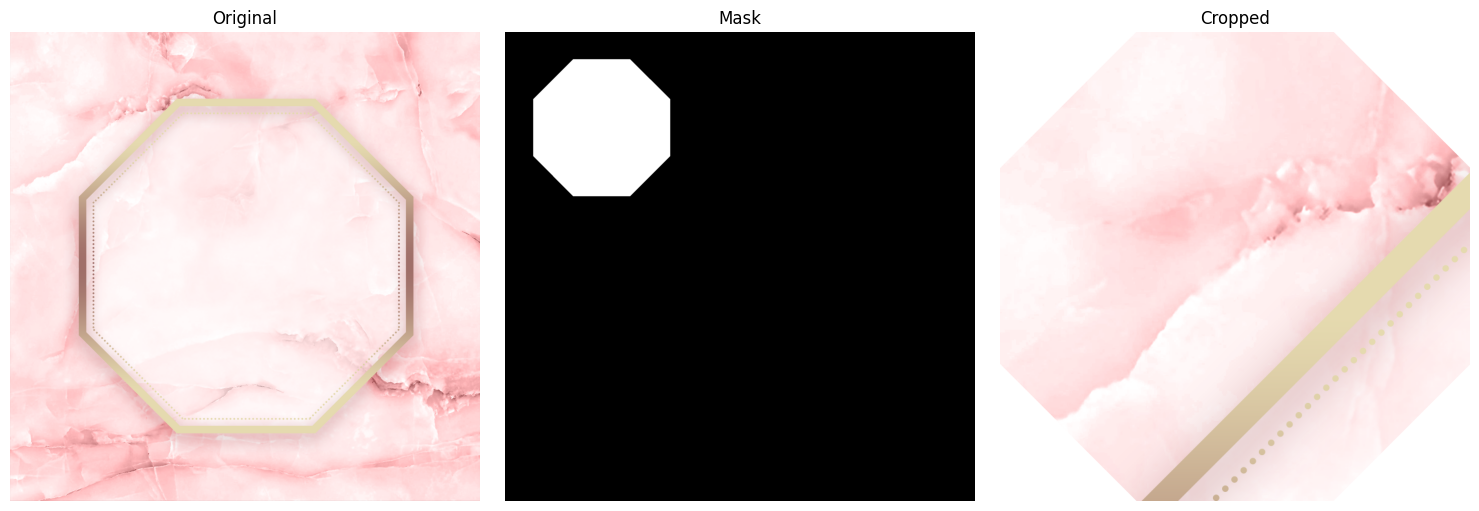

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# 1. 讀圖
img = Image.open("irregular2.png").convert("RGB")   # 換成你的檔名
W, H = img.size

# 2. 八邊形頂點 (x, y),依順時針排列(依 1024x1024 估計)
pts = [
    (362, 150), (665, 150),   # 上緣
    (878, 362), (878, 665),   # 右緣
    (665, 878), (362, 878),   # 下緣
    (150, 665), (150, 362),   # 左緣
]

# 3. 建立 mask(多邊形內為 255,外面為 0)
mask = Image.new("L", (W, H), 0)
ImageDraw.Draw(mask).polygon(pts, fill=255)

# 4. 套用 mask:外面變透明
rgba = img.copy()
rgba.putalpha(mask)

# 5. 裁到多邊形的外接矩形(可省略)
xs, ys = zip(*pts)
cropped = rgba.crop((min(xs), min(ys), max(xs), max(ys)))

# 6. matplotlib 顯示
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img);                axes[0].set_title("Original")
axes[1].imshow(mask, cmap="gray");  axes[1].set_title("Mask")
axes[2].imshow(cropped);            axes[2].set_title("Cropped")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 存成透明背景 PNG
cropped.save("octagon_cut.png")




## 2.全域閾值模式 (Global Thresholding)

### THRESH_BINARY 二值化處理

$
\text{THRESH_BINARY}:\quad
\mathrm{dst}(x,y) =
\begin{cases}
\mathit{maxval}, & \mathrm{src}(x,y) > T \\[4pt]
0, & \mathrm{src}(x,y) \le T
\end{cases}
$


src  shape   : (371, 538)   dtype: uint8
mask shape   : (371, 538)  dtype: uint8
threshold    : 127.0          (THRESH_BINARY)
白色 (255)   :    40724 px  (20.40%)
黑色 (0)     :   158874 px  (79.60%)
相異值       : {0: 158874, 255: 40724}

ROI slice    : [179:191, 261:277]  shape = (12, 16)
roi_src（灰階 0-255）：
[[217 227 237 248 249 249 246 242 238 237 237 232 231 230 229 226]
 [221 232 240 245 246 246 243 237 232 230 229 223 221 219 216 212]
 [230 239 245 243 243 242 237 229 221 217 215 213 210 206 202 199]
 [233 242 249 247 247 243 235 224 213 206 202 195 193 190 189 191]
 [231 240 250 254 253 248 238 224 211 201 197 179 177 177 181 189]
 [239 247 249 250 249 244 233 219 207 201 199 192 189 186 186 191]
 [250 251 248 246 244 239 228 214 202 195 192 200 200 202 205 209]
 [255 254 250 247 245 238 227 214 203 196 193 201 205 210 215 218]
 [253 253 252 253 248 238 227 216 208 204 203 201 203 206 210 213]
 [251 249 246 250 242 231 221 213 210 210 210 203 201 198 197 199]
 [253 244 235 234 227 219

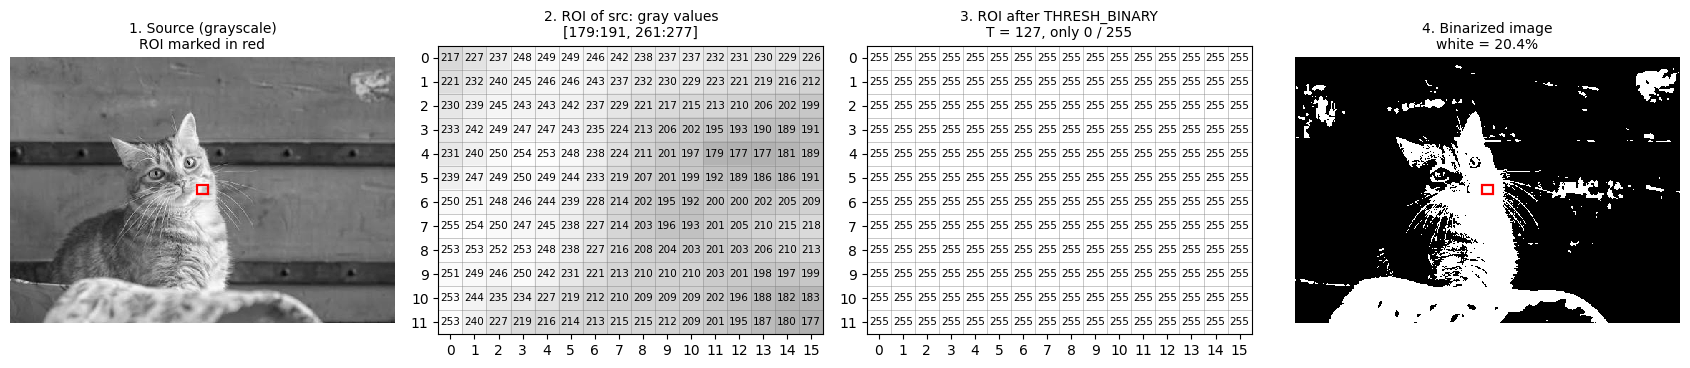

In [ ]:
# -*- coding: utf-8 -*-
"""
THRESH_BINARY binarization demo
  [1] original      [2] grayscale ROI of src
  [3] binarized ROI   [4] full binarized image
"""
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------- 參數 ----------------
PATH   = "images.jpg"
THRESH = 127
MAXVAL = 255
ROI_H  = 12           # ROI 高度（列）
ROI_W  = 16           # ROI 寬度（行）

# ---------------- 讀圖 + 二值化 ----------------
src = cv2.imread(PATH, cv2.IMREAD_GRAYSCALE)
if src is None:
    raise FileNotFoundError(f"讀不到影像：{PATH}")

ret, mask = cv2.threshold(src, THRESH, MAXVAL, cv2.THRESH_BINARY)

# ---------------- 1. mask 資訊 ----------------
h, w  = mask.shape[:2]
white = int(np.count_nonzero(mask))
total = int(mask.size)

print("=" * 54)
print(f"src  shape   : {src.shape}   dtype: {src.dtype}")
print(f"mask shape   : {mask.shape}  dtype: {mask.dtype}")
print(f"threshold    : {ret}          (THRESH_BINARY)")
print(f"白色 (255)   : {white:>8d} px  ({white / total:6.2%})")
print(f"黑色 (0)     : {total - white:>8d} px  ({(total - white) / total:6.2%})")
print("=" * 54)

# ---------------- 2. mask 的值 ----------------
vals, counts = np.unique(mask, return_counts=True)
print("相異值       :", dict(zip(vals.tolist(), counts.tolist())))

# 切出中央 ROI（夾在合法範圍，避免小圖越界）
r0 = max(0, min(h // 2 - ROI_H // 2, h - ROI_H))
c0 = max(0, min(w // 2 - ROI_W // 2, w - ROI_W))
roi_src  = src [r0:r0 + ROI_H, c0:c0 + ROI_W]
roi_mask = mask[r0:r0 + ROI_H, c0:c0 + ROI_W]

np.set_printoptions(linewidth=200, threshold=10000)
print(f"\nROI slice    : [{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]  shape = {roi_mask.shape}")
print(f"roi_src（灰階 0-255）：\n{roi_src}")
print(f"roi_mask（只有 0 / 255）：\n{roi_mask}")
print(f"ROI 白色占比 : {np.count_nonzero(roi_mask) / roi_mask.size:.1%}\n")

# ---------------- 3. matplotlib 顯示（四格）----------------
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))

# --- [1] 原圖 ---
ax = axes[0]
ax.imshow(src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title(f"1. Source (grayscale)\nROI marked in red", fontsize=10)
ax.axis("off")

# --- [2] 原圖上的灰階 ROI ---
ax = axes[1]
ax.imshow(roi_src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_src):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v <= THRESH else "black")     # 紅字 = 會被歸 0
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"2. ROI of src: gray values\n[{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]",
             fontsize=10)

# --- [3] 二值化後的 ROI ---
ax = axes[2]
ax.imshow(roi_mask, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_mask):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v == 0 else "black")
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"3. ROI after THRESH_BINARY\nT = {THRESH}, only 0 / 255", fontsize=10)

# --- [4] 全圖二值化結果 ---
ax = axes[3]
ax.imshow(mask, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title(f"4. Binarized image\nwhite = {white/total:.1%}", fontsize=10)
ax.axis("off")

plt.tight_layout()
plt.savefig("thresh_binary_4panel.png", dpi=150, bbox_inches="tight")
plt.show()




### THRESH_BINARY_INV 反二值化處理

$$
\text{THRESH_BINARY_INV}:\quad
\mathrm{dst}(x,y) =
\begin{cases}
0, & \mathrm{src}(x,y) > T \\[4pt]
\mathit{maxval}, & \mathrm{src}(x,y) \le T
\end{cases}
$$


mode         : THRESH_BINARY_INV
src  shape   : (371, 538)   dtype: uint8
mask shape   : (371, 538)  dtype: uint8
ret          : 127.0          (實際套用的閾值)
白色 (255)   :   158874 px  (79.60%)   <- 暗部
黑色 (0)     :    40724 px  (20.40%)   <- 亮部
相異值       : {0: 40724, 255: 158874}

ROI slice    : [179:191, 261:277]  shape = (12, 16)
roi_src（灰階 0-255）：
[[217 227 237 248 249 249 246 242 238 237 237 232 231 230 229 226]
 [221 232 240 245 246 246 243 237 232 230 229 223 221 219 216 212]
 [230 239 245 243 243 242 237 229 221 217 215 213 210 206 202 199]
 [233 242 249 247 247 243 235 224 213 206 202 195 193 190 189 191]
 [231 240 250 254 253 248 238 224 211 201 197 179 177 177 181 189]
 [239 247 249 250 249 244 233 219 207 201 199 192 189 186 186 191]
 [250 251 248 246 244 239 228 214 202 195 192 200 200 202 205 209]
 [255 254 250 247 245 238 227 214 203 196 193 201 205 210 215 218]
 [253 253 252 253 248 238 227 216 208 204 203 201 203 206 210 213]
 [251 249 246 250 242 231 221 213 210 210 210 203

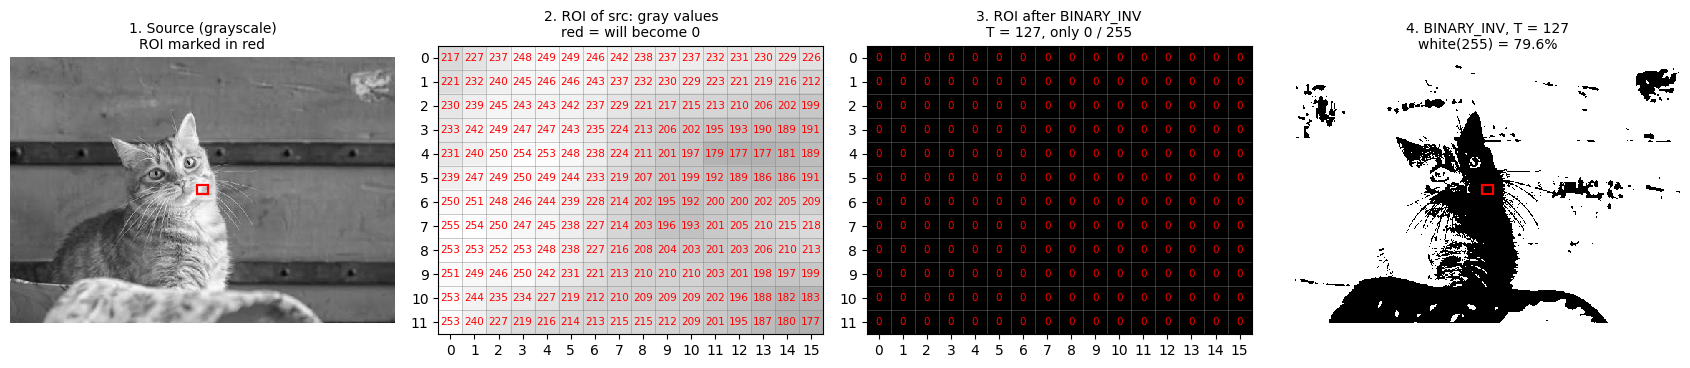

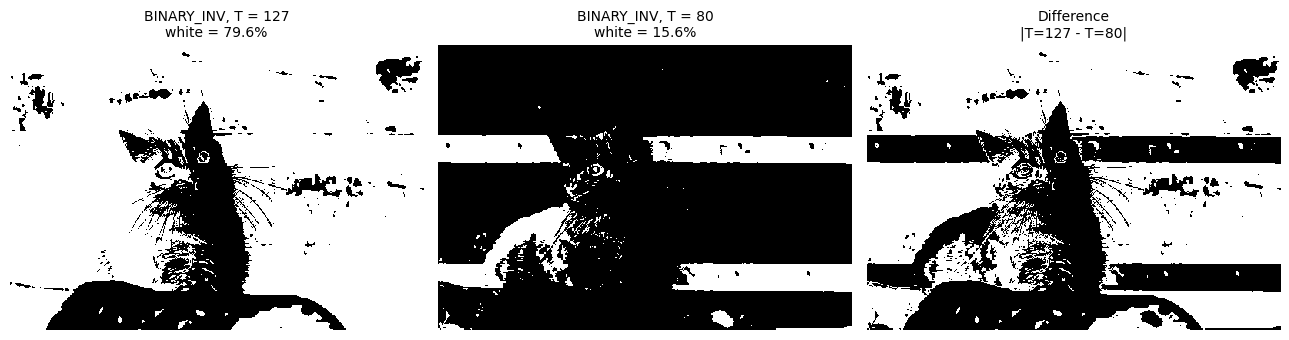

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

try:                                    # Colab 才有，本機跑會 ImportError
    from google.colab.patches import cv2_imshow
    HAS_COLAB = True
except ImportError:
    HAS_COLAB = False

# ---------------- 參數 ----------------
PATH    = "images.jpg"
MAXVAL  = 255
THRESH  = 127          # 主示範閾值
THRESH2 = 80           # 對照閾值（你原本改的那個）
ROI_H   = 12
ROI_W   = 16

# ---------------- 讀圖 + 反二值化 ----------------
src = cv2.imread(PATH, cv2.IMREAD_GRAYSCALE)
if src is None:
    raise FileNotFoundError(f"讀不到影像：{PATH}")

ret, mask = cv2.threshold(src, THRESH, MAXVAL, cv2.THRESH_BINARY_INV)

# ---------------- 1. mask 資訊 ----------------
h, w  = mask.shape[:2]
white = int(np.count_nonzero(mask))
total = int(mask.size)

print("=" * 58)
print(f"mode         : THRESH_BINARY_INV")
print(f"src  shape   : {src.shape}   dtype: {src.dtype}")
print(f"mask shape   : {mask.shape}  dtype: {mask.dtype}")
print(f"ret          : {ret}          (實際套用的閾值)")
print(f"白色 (255)   : {white:>8d} px  ({white / total:6.2%})   <- 暗部")
print(f"黑色 (0)     : {total - white:>8d} px  ({(total - white) / total:6.2%})   <- 亮部")
print("=" * 58)

# ---------------- 2. mask 的值 ----------------
vals, counts = np.unique(mask, return_counts=True)
print("相異值       :", dict(zip(vals.tolist(), counts.tolist())))

# 切出中央 ROI（夾在合法範圍，避免小圖越界）
r0 = max(0, min(h // 2 - ROI_H // 2, h - ROI_H))
c0 = max(0, min(w // 2 - ROI_W // 2, w - ROI_W))
roi_src  = src [r0:r0 + ROI_H, c0:c0 + ROI_W]
roi_mask = mask[r0:r0 + ROI_H, c0:c0 + ROI_W]

np.set_printoptions(linewidth=200, threshold=10000)
print(f"\nROI slice    : [{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]  shape = {roi_mask.shape}")
print(f"roi_src（灰階 0-255）：\n{roi_src}")
print(f"roi_mask（BINARY_INV，只有 0 / 255）：\n{roi_mask}")
print(f"ROI 白色占比 : {np.count_nonzero(roi_mask) / roi_mask.size:.1%}\n")

# ---------------- 3. matplotlib 顯示（四格）----------------
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))

# --- [1] 原圖（紅框標 ROI）---
ax = axes[0]
ax.imshow(src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title("1. Source (grayscale)\nROI marked in red", fontsize=10)
ax.axis("off")

# --- [2] 原圖上的灰階 ROI ---
ax = axes[1]
ax.imshow(roi_src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_src):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v > THRESH else "black")   # 紅字 = INV 後會變 0
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"2. ROI of src: gray values\nred = will become 0",
             fontsize=10)

# --- [3] 反二值化後的 ROI ---
ax = axes[2]
ax.imshow(roi_mask, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_mask):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v == 0 else "black")
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"3. ROI after BINARY_INV\nT = {THRESH}, only 0 / 255",
             fontsize=10)

# --- [4] 全圖反二值化 ---
ax = axes[3]
ax.imshow(mask, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title(f"4. BINARY_INV, T = {THRESH}\nwhite(255) = {white/total:.1%}",
             fontsize=10)
ax.axis("off")

plt.tight_layout()
plt.savefig("binary_inv_4panel.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- 4. T = 127 vs T = 80 ----------------
_, m80 = cv2.threshold(src, THRESH2, MAXVAL, cv2.THRESH_BINARY_INV)

fig2, axes2 = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, t, m in zip(axes2, [THRESH, THRESH2, None], [mask, m80, None]):
    if m is None:
        ax.imshow(mask - m80 if False else cv2.absdiff(mask, m80),
                  cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(f"Difference\n|T={THRESH} - T={THRESH2}|", fontsize=10)
    else:
        ax.imshow(m, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(f"BINARY_INV, T = {t}\nwhite = {np.count_nonzero(m)/m.size:.1%}",
                     fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("binary_inv_compare.png", dpi=150, bbox_inches="tight")
plt.show()

### THRESH_TRUNC 截斷閥值處理

$$
\mathrm{dst}(x,y) =
\begin{cases}
T, & \text{if } \mathrm{src}(x,y) > T \\[4pt]
\mathrm{src}(x,y), & \text{otherwise}
\end{cases}
$$


mode         : THRESH_TRUNC  (不是二值化!)
src  shape   : (371, 538)   dtype: uint8
ret          : 127.0          (實際套用的閾值)
src  值域    : 0 ~ 255
dst  值域    : 0 ~ 127   <- 上限就是 T，不是 255
被截斷像素   :    40724 px  (20.40%)
未變動像素   :   158874 px  (79.60%)
相異值個數   : 126   <- TRUNC 不會只剩 2 個
峰值（最多） : 127 出現 42441 px  <- 就是 T 那一堆
值域檢查     : dst.max() = 127  ( 應等於 T = 127 )

ROI slice    : [179:191, 261:277]  shape = (12, 16)
roi_src（原始灰階）：
[[217 227 237 248 249 249 246 242 238 237 237 232 231 230 229 226]
 [221 232 240 245 246 246 243 237 232 230 229 223 221 219 216 212]
 [230 239 245 243 243 242 237 229 221 217 215 213 210 206 202 199]
 [233 242 249 247 247 243 235 224 213 206 202 195 193 190 189 191]
 [231 240 250 254 253 248 238 224 211 201 197 179 177 177 181 189]
 [239 247 249 250 249 244 233 219 207 201 199 192 189 186 186 191]
 [250 251 248 246 244 239 228 214 202 195 192 200 200 202 205 209]
 [255 254 250 247 245 238 227 214 203 196 193 201 205 210 215 218]
 [253 253 252 253 248 238 227 216 20

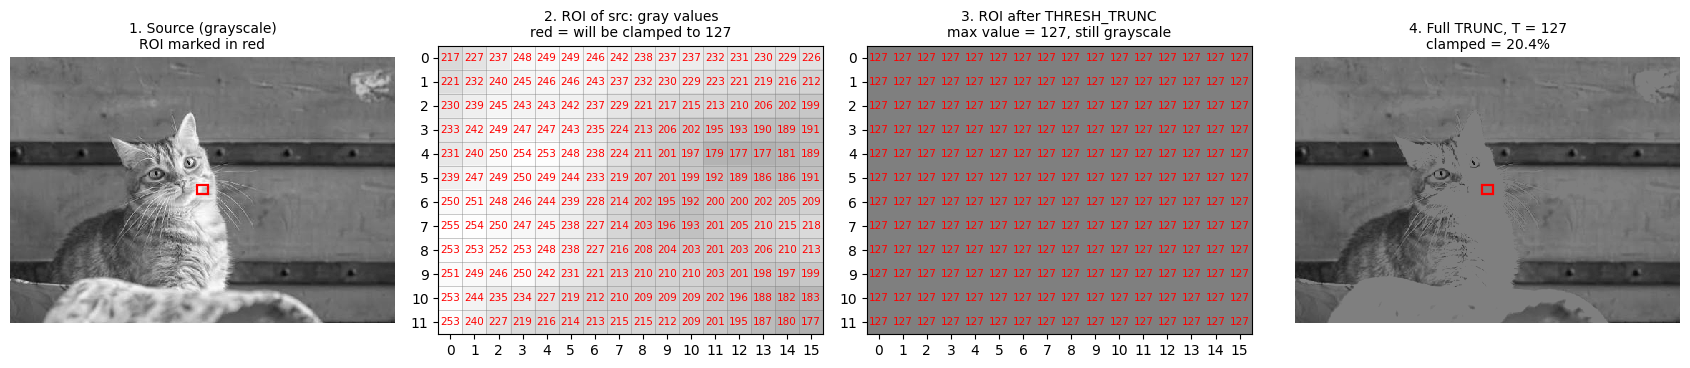

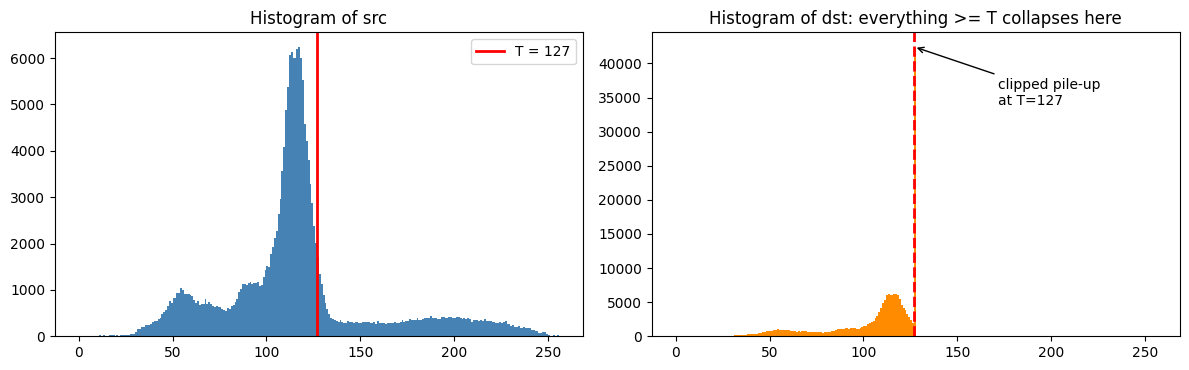

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------- 參數 ----------------
PATH   = "images.jpg"
THRESH = 127
MAXVAL = 255          # 對 TRUNC 無效，僅為保持 API 一致
ROI_H  = 12
ROI_W  = 16

# ---------------- 讀圖 + 截斷 ----------------
src = cv2.imread(PATH, cv2.IMREAD_GRAYSCALE)
if src is None:
    raise FileNotFoundError(f"讀不到影像：{PATH}")

ret, dst = cv2.threshold(src, THRESH, MAXVAL, cv2.THRESH_TRUNC)

# ---------------- 1. dst 資訊 ----------------
h, w = dst.shape[:2]
truncated = int(np.count_nonzero(src > THRESH))     # 被壓成 127 的像素數
total     = int(dst.size)

print("=" * 58)
print(f"mode         : THRESH_TRUNC  (不是二值化!)")
print(f"src  shape   : {src.shape}   dtype: {src.dtype}")
print(f"ret          : {ret}          (實際套用的閾值)")
print(f"src  值域    : {src.min()} ~ {src.max()}")
print(f"dst  值域    : {dst.min()} ~ {dst.max()}   <- 上限就是 T，不是 255")
print(f"被截斷像素   : {truncated:>8d} px  ({truncated/total:6.2%})")
print(f"未變動像素   : {total-truncated:>8d} px  ({(total-truncated)/total:6.2%})")
print("=" * 58)

# ---------------- 2. dst 的值 ----------------
vals, counts = np.unique(dst, return_counts=True)
print(f"相異值個數   : {len(vals)}   <- TRUNC 不會只剩 2 個")
print(f"峰值（最多） : {vals[counts.argmax()]} 出現 {counts.max()} px"
      f"  <- 就是 T 那一堆")
print(f"值域檢查     : dst.max() = {dst.max()}  ( 應等於 T = {THRESH} )")

# 切出中央 ROI（夾在合法範圍，避免小圖越界）
r0 = max(0, min(h // 2 - ROI_H // 2, h - ROI_H))
c0 = max(0, min(w // 2 - ROI_W // 2, w - ROI_W))
roi_src = src[r0:r0 + ROI_H, c0:c0 + ROI_W]
roi_dst = dst[r0:r0 + ROI_H, c0:c0 + ROI_W]

np.set_printoptions(linewidth=200, threshold=10000)
print(f"\nROI slice    : [{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]  shape = {roi_dst.shape}")
print(f"roi_src（原始灰階）：\n{roi_src}")
print(f"roi_dst（TRUNC 後，超過 {THRESH} 的都是 {THRESH}）：\n{roi_dst}")

# ---------------- 3. matplotlib 顯示（四格）----------------
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))

# --- [1] 原圖 ---
ax = axes[0]
ax.imshow(src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title("1. Source (grayscale)\nROI marked in red", fontsize=10)
ax.axis("off")

# --- [2] 原圖上的灰階 ROI ---
ax = axes[1]
ax.imshow(roi_src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_src):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v > THRESH else "black")   # 紅字 = 會被壓成 127
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"2. ROI of src: gray values\nred = will be clamped to {THRESH}",
             fontsize=10)

# --- [3] TRUNC 後的 ROI ---
ax = axes[2]
ax.imshow(roi_dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_dst):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v == THRESH and roi_src[j, i] > THRESH else "black")
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"3. ROI after THRESH_TRUNC\nmax value = {THRESH}, still grayscale",
             fontsize=10)

# --- [4] 全圖 TRUNC ---
ax = axes[3]
ax.imshow(dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title(f"4. Full TRUNC, T = {THRESH}\nclamped = {truncated/total:.1%}",
             fontsize=10)
ax.axis("off")

plt.tight_layout()
plt.savefig("trunc_4panel.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- 4. 直方圖：看那一根尖峰 ----------------
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 3.8))
axes2[0].hist(src.ravel(), bins=256, range=(0, 256), color="steelblue")
axes2[0].axvline(THRESH, color="red", lw=2, label=f"T = {THRESH}")
axes2[0].set_title("Histogram of src"); axes2[0].legend()

axes2[1].hist(dst.ravel(), bins=256, range=(0, 256), color="darkorange")
axes2[1].axvline(THRESH, color="red", lw=2, ls="--")
axes2[1].annotate(f"clipped pile-up\nat T={THRESH}", xy=(THRESH, counts.max()),
                  xytext=(THRESH + 45, counts.max() * 0.8),
                  arrowprops=dict(arrowstyle="->", color="black"))
axes2[1].set_title("Histogram of dst: everything >= T collapses here")
plt.tight_layout()
plt.savefig("trunc_hist.png", dpi=150, bbox_inches="tight")
plt.show()


### THRESH_TOZERO 低閥值用0處理

$$
\text{THRESH_TOZERO}:\quad
\mathrm{dst}(x,y) =
\begin{cases}
0, & \mathrm{src}(x,y) \le T \\[4pt]
\mathrm{src}(x,y), & \mathrm{src}(x,y) > T
\end{cases}
$$


mode         : THRESH_TOZERO  (不是二值化!)
src  shape   : (371, 538)   dtype: uint8
ret          : 127.0          (實際套用的閾值)
src  值域    : 0 ~ 255
dst  值域    : 0 ~ 255   <- 上限仍是 255
被歸零像素   :   158874 px  (79.60%)  (src <= 127)
保留原值像素 :    40724 px  (20.40%)  (src >  127)
相異值個數   : 129   <- TOZERO 不會只剩 2 個
最小值       : 0  出現 158874 px  <- 歸零那一堆
第二小值     : 128  <- 應大於 T=127，中間沒有值
值域檢查     : (0 或 > T) ?  True

ROI slice    : [179:191, 261:277]  shape = (12, 16)
roi_src（原始灰階）：
[[217 227 237 248 249 249 246 242 238 237 237 232 231 230 229 226]
 [221 232 240 245 246 246 243 237 232 230 229 223 221 219 216 212]
 [230 239 245 243 243 242 237 229 221 217 215 213 210 206 202 199]
 [233 242 249 247 247 243 235 224 213 206 202 195 193 190 189 191]
 [231 240 250 254 253 248 238 224 211 201 197 179 177 177 181 189]
 [239 247 249 250 249 244 233 219 207 201 199 192 189 186 186 191]
 [250 251 248 246 244 239 228 214 202 195 192 200 200 202 205 209]
 [255 254 250 247 245 238 227 214 203 196 193 201 205 210 2

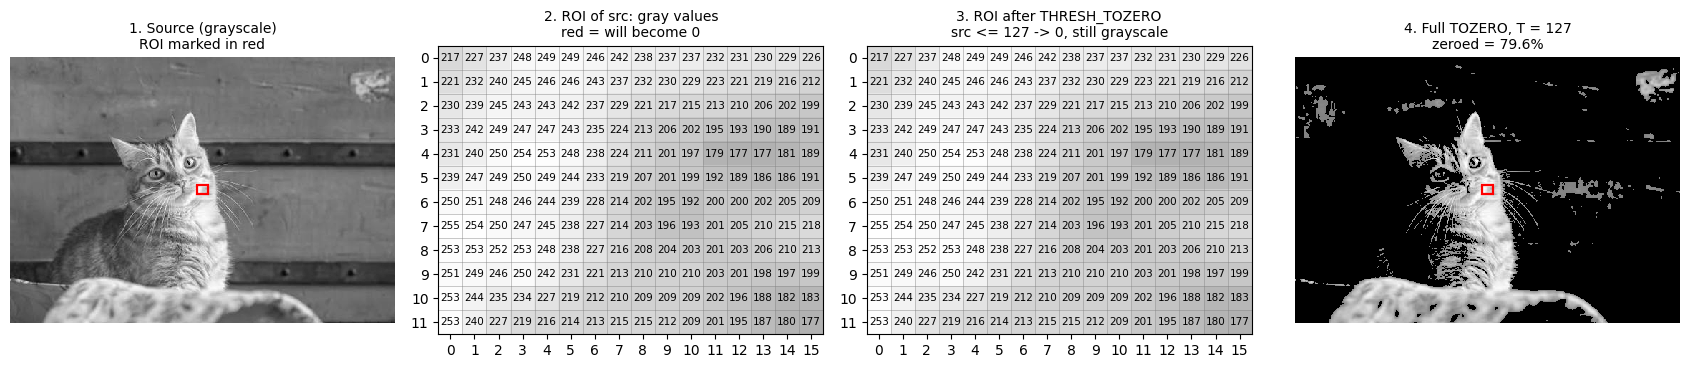

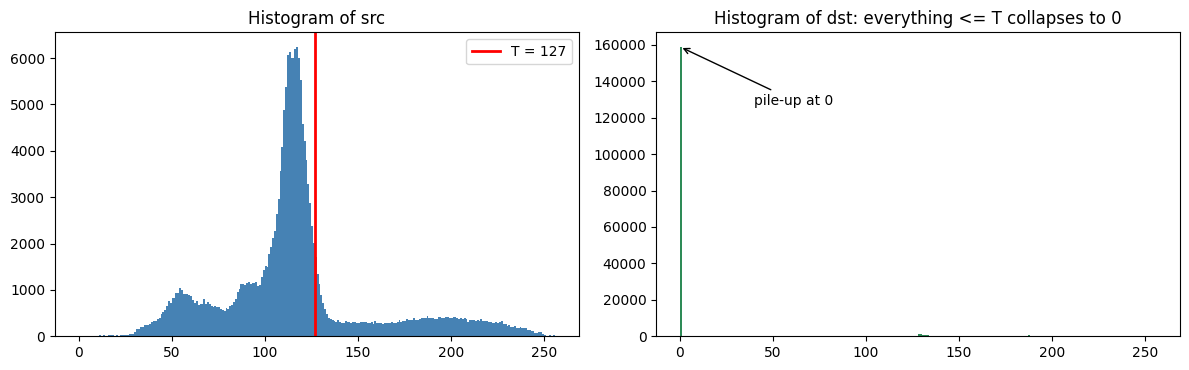

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------- 參數 ----------------
PATH   = "images.jpg"
THRESH = 127
MAXVAL = 255          # TRUNC / TOZERO 都不使用它
ROI_H  = 12
ROI_W  = 16

# ---------------- 讀圖 + TOZERO ----------------
src = cv2.imread(PATH, cv2.IMREAD_GRAYSCALE)
if src is None:
    raise FileNotFoundError(f"讀不到影像：{PATH}")

ret, dst = cv2.threshold(src, THRESH, MAXVAL, cv2.THRESH_TOZERO)

# ---------------- 1. dst 資訊 ----------------
h, w  = dst.shape[:2]
zeroed = int(np.count_nonzero(src <= THRESH))   # 被歸零的像素
total  = int(dst.size)
kept   = total - zeroed

print("=" * 58)
print(f"mode         : THRESH_TOZERO  (不是二值化!)")
print(f"src  shape   : {src.shape}   dtype: {src.dtype}")
print(f"ret          : {ret}          (實際套用的閾值)")
print(f"src  值域    : {src.min()} ~ {src.max()}")
print(f"dst  值域    : {dst.min()} ~ {dst.max()}   <- 上限仍是 255")
print(f"被歸零像素   : {zeroed:>8d} px  ({zeroed/total:6.2%})  (src <= {THRESH})")
print(f"保留原值像素 : {kept:>8d} px  ({kept/total:6.2%})  (src >  {THRESH})")
print("=" * 58)

# ---------------- 2. dst 的值 ----------------
vals, counts = np.unique(dst, return_counts=True)
print(f"相異值個數   : {len(vals)}   <- TOZERO 不會只剩 2 個")
print(f"最小值       : {vals.min()}  出現 {counts[vals == vals.min()][0]} px  <- 歸零那一堆")
print(f"第二小值     : {vals[1]}  <- 應大於 T={THRESH}，中間沒有值")
print(f"值域檢查     : (0 或 > T) ?  "
      f"{bool(np.all((dst == 0) | (dst > THRESH)))}")

# 切出中央 ROI（夾在合法範圍，避免小圖越界）
r0 = max(0, min(h // 2 - ROI_H // 2, h - ROI_H))
c0 = max(0, min(w // 2 - ROI_W // 2, w - ROI_W))
roi_src = src[r0:r0 + ROI_H, c0:c0 + ROI_W]
roi_dst = dst[r0:r0 + ROI_H, c0:c0 + ROI_W]

np.set_printoptions(linewidth=200, threshold=10000)
print(f"\nROI slice    : [{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]  shape = {roi_dst.shape}")
print(f"roi_src（原始灰階）：\n{roi_src}")
print(f"roi_dst（TOZERO 後，<= {THRESH} 的全變 0）：\n{roi_dst}")

# ---------------- 3. matplotlib 顯示（四格）----------------
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))

# --- [1] 原圖 ---
ax = axes[0]
ax.imshow(src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title("1. Source (grayscale)\nROI marked in red", fontsize=10)
ax.axis("off")

# --- [2] 原圖上的灰階 ROI ---
ax = axes[1]
ax.imshow(roi_src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_src):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v <= THRESH else "black")   # 紅字 = 會被歸 0
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"2. ROI of src: gray values\nred = will become 0", fontsize=10)

# --- [3] TOZERO 後的 ROI ---
ax = axes[2]
ax.imshow(roi_dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_dst):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v == 0 else "black")
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"3. ROI after THRESH_TOZERO\nsrc <= {THRESH} -> 0, still grayscale",
             fontsize=10)

# --- [4] 全圖 TOZERO ---
ax = axes[3]
ax.imshow(dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title(f"4. Full TOZERO, T = {THRESH}\nzeroed = {zeroed/total:.1%}",
             fontsize=10)
ax.axis("off")

plt.tight_layout()
plt.savefig("tozero_4panel.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- 4. 直方圖：看 0 那一根尖峰 ----------------
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 3.8))

axes2[0].hist(src.ravel(), bins=256, range=(0, 256), color="steelblue")
axes2[0].axvline(THRESH, color="red", lw=2, label=f"T = {THRESH}")
axes2[0].set_title("Histogram of src"); axes2[0].legend()

axes2[1].hist(dst.ravel(), bins=256, range=(0, 256), color="seagreen")
axes2[1].annotate(f"pile-up at 0", xy=(0, counts.max()),
                  xytext=(40, counts.max() * 0.8),
                  arrowprops=dict(arrowstyle="->", color="black"))
axes2[1].set_title("Histogram of dst: everything <= T collapses to 0")
plt.tight_layout()
plt.savefig("tozero_hist.png", dpi=150, bbox_inches="tight")
plt.show()

### THRESH_TOZERO_INV 高閥值用0處理

$$
\text{THRESH_TOZERO_INV}:\quad
\mathrm{dst}(x,y) =
\begin{cases}
\mathrm{src}(x,y), & \mathrm{src}(x,y) \le T \\[4pt]
0, & \mathrm{src}(x,y) > T
\end{cases}
$$


mode         : THRESH_TOZERO_INV  (不是二值化!)
src  shape   : (371, 538)   dtype: uint8
ret          : 127.0          (實際套用的閾值)
src  值域    : 0 ~ 255
dst  值域    : 0 ~ 127   <- 上限被壓到 T
被歸零像素   :    40724 px  (20.40%)  (src >  127)
保留原值像素 :   158874 px  (79.60%)  (src <= 127)
相異值個數   : 126   <- 不會只剩 2 個
最大值       : 127   <- 應等於 T = 127
值域檢查     : dst.max() <= T ? True
0 的像素數   : 40726  px
  其中原本就是 0 的 : 2 px
  其中被歸零的     : 40724 px   <- 這些資訊已經永久遺失

ROI slice    : [179:191, 261:277]  shape = (12, 16)
roi_src（原始灰階）：
[[217 227 237 248 249 249 246 242 238 237 237 232 231 230 229 226]
 [221 232 240 245 246 246 243 237 232 230 229 223 221 219 216 212]
 [230 239 245 243 243 242 237 229 221 217 215 213 210 206 202 199]
 [233 242 249 247 247 243 235 224 213 206 202 195 193 190 189 191]
 [231 240 250 254 253 248 238 224 211 201 197 179 177 177 181 189]
 [239 247 249 250 249 244 233 219 207 201 199 192 189 186 186 191]
 [250 251 248 246 244 239 228 214 202 195 192 200 200 202 205 209]
 [255 254 250 247 

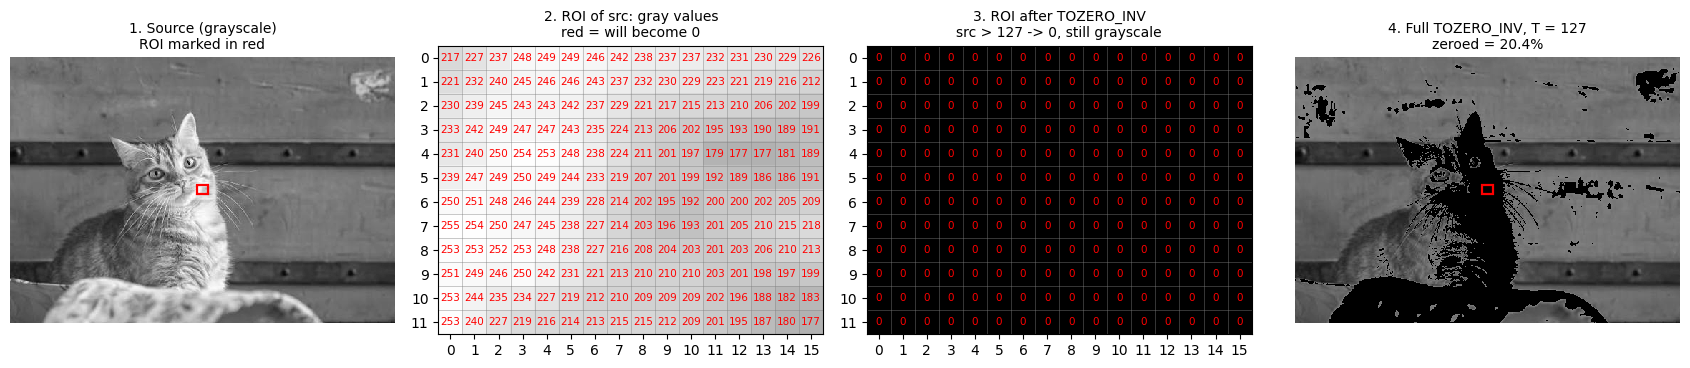

/tmp/ipykernel_720/3356374036.py:129: UserWarning: Glyph 35519 (\N{CJK UNIFIED IDEOGRAPH-8ABF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_720/3356374036.py:129: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_720/3356374036.py:129: UserWarning: Glyph 26356 (\N{CJK UNIFIED IDEOGRAPH-66F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_720/3356374036.py:129: UserWarning: Glyph 22810 (\N{CJK UNIFIED IDEOGRAPH-591A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_720/3356374036.py:129: UserWarning: Glyph 20142 (\N{CJK UNIFIED IDEOGRAPH-4EAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_720/3356374036.py:129: UserWarning: Glyph 37096 (\N{CJK UNIFIED IDEOGRAPH-90E8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_720/3356374036.py:129: UserWarning: Glyph 34987 (\N{CJK UNIFIED IDEOGRAPH-88AB}

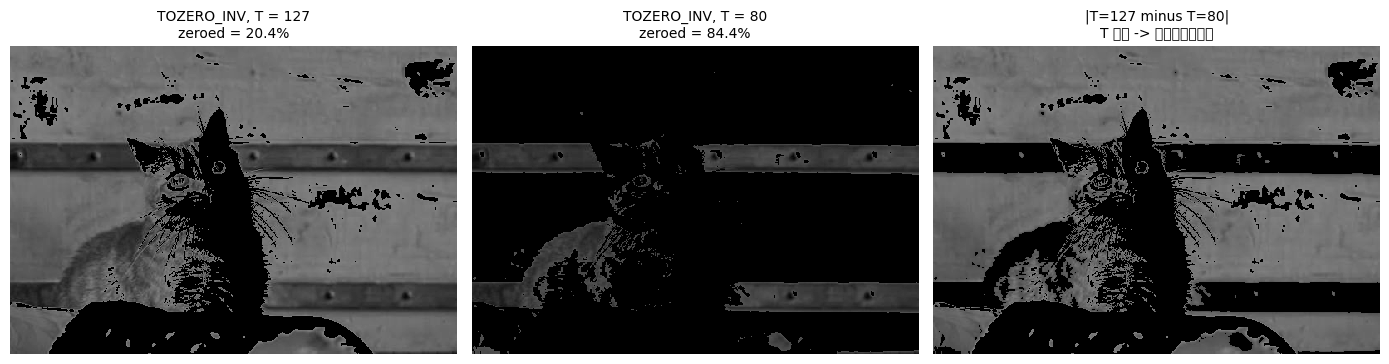

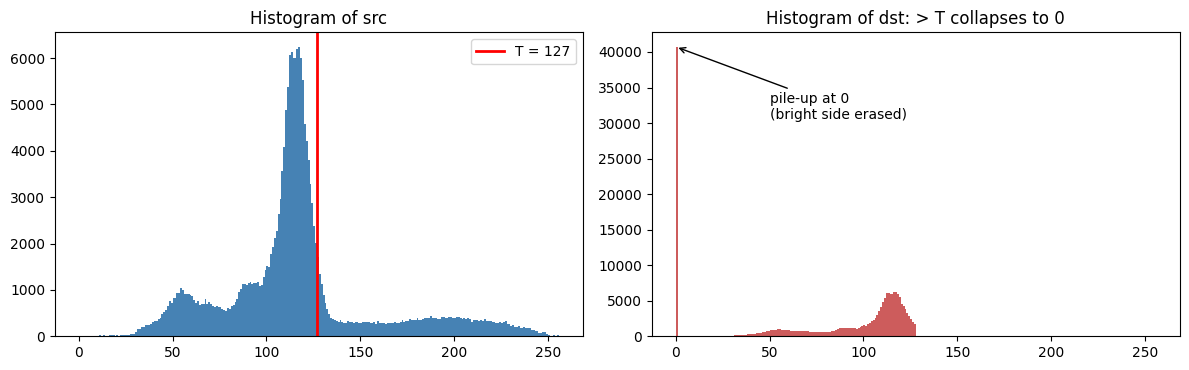

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab.patches import cv2_imshow
    HAS_COLAB = True
except ImportError:
    HAS_COLAB = False

# ---------------- 參數 ----------------
PATH    = "images.jpg"
MAXVAL  = 255          # TOZERO_INV 不使用 maxval
THRESH  = 127
THRESH2 = 80           # 你原稿改的那個
ROI_H   = 12
ROI_W   = 16

# ---------------- 讀圖 + TOZERO_INV ----------------
src = cv2.imread(PATH, cv2.IMREAD_GRAYSCALE)
if src is None:
    raise FileNotFoundError(f"讀不到影像：{PATH}")

ret, dst = cv2.threshold(src, THRESH, MAXVAL, cv2.THRESH_TOZERO_INV)

# ---------------- 1. dst 資訊 ----------------
h, w    = dst.shape[:2]
zeroed  = int(np.count_nonzero(src > THRESH))      # 被歸零（亮部）
total   = int(dst.size)
kept    = total - zeroed

print("=" * 60)
print(f"mode         : THRESH_TOZERO_INV  (不是二值化!)")
print(f"src  shape   : {src.shape}   dtype: {src.dtype}")
print(f"ret          : {ret}          (實際套用的閾值)")
print(f"src  值域    : {src.min()} ~ {src.max()}")
print(f"dst  值域    : {dst.min()} ~ {dst.max()}   <- 上限被壓到 T")
print(f"被歸零像素   : {zeroed:>8d} px  ({zeroed/total:6.2%})  (src >  {THRESH})")
print(f"保留原值像素 : {kept:>8d} px  ({kept/total:6.2%})  (src <= {THRESH})")
print("=" * 60)

# ---------------- 2. dst 的值 ----------------
vals, counts = np.unique(dst, return_counts=True)
print(f"相異值個數   : {len(vals)}   <- 不會只剩 2 個")
print(f"最大值       : {vals.max()}   <- 應等於 T = {THRESH}")
print(f"值域檢查     : dst.max() <= T ? {dst.max() <= THRESH}")
print(f"0 的像素數   : {int((dst == 0).sum())}  px")
print(f"  其中原本就是 0 的 : {int((src == 0).sum())} px")
print(f"  其中被歸零的     : {int(((src > THRESH) & (dst == 0)).sum())} px"
      f"   <- 這些資訊已經永久遺失")

# 切出中央 ROI
r0 = max(0, min(h // 2 - ROI_H // 2, h - ROI_H))
c0 = max(0, min(w // 2 - ROI_W // 2, w - ROI_W))
roi_src = src[r0:r0 + ROI_H, c0:c0 + ROI_W]
roi_dst = dst[r0:r0 + ROI_H, c0:c0 + ROI_W]

np.set_printoptions(linewidth=200, threshold=10000)
print(f"\nROI slice    : [{r0}:{r0+ROI_H}, {c0}:{c0+ROI_W}]  shape = {roi_dst.shape}")
print(f"roi_src（原始灰階）：\n{roi_src}")
print(f"roi_dst（> {THRESH} 者全變 0）：\n{roi_dst}")

# ---------------- 3. matplotlib 顯示（四格）----------------
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))

# --- [1] 原圖 ---
ax = axes[0]
ax.imshow(src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title("1. Source (grayscale)\nROI marked in red", fontsize=10)
ax.axis("off")

# --- [2] 原圖上的灰階 ROI ---
ax = axes[1]
ax.imshow(roi_src, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_src):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v > THRESH else "black")    # 紅字 = 會被歸 0
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title("2. ROI of src: gray values\nred = will become 0", fontsize=10)

# --- [3] TOZERO_INV 後的 ROI ---
ax = axes[2]
ax.imshow(roi_dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for (j, i), v in np.ndenumerate(roi_dst):
    ax.text(i, j, str(v), ha="center", va="center", fontsize=7.5,
            color="red" if v == 0 else "black")
ax.set_xticks(range(ROI_W)); ax.set_yticks(range(ROI_H))
ax.set_xticks(np.arange(-0.5, ROI_W, 1), minor=True)
ax.set_yticks(np.arange(-0.5, ROI_H, 1), minor=True)
ax.grid(which="minor", color="gray", lw=0.5, alpha=0.6)
ax.tick_params(which="minor", length=0)
ax.set_title(f"3. ROI after TOZERO_INV\nsrc > {THRESH} -> 0, still grayscale",
             fontsize=10)

# --- [4] 全圖 TOZERO_INV ---
ax = axes[3]
ax.imshow(dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), ROI_W, ROI_H,
                           fill=False, edgecolor="red", lw=1.6))
ax.set_title(f"4. Full TOZERO_INV, T = {THRESH}\nzeroed = {zeroed/total:.1%}",
             fontsize=10)
ax.axis("off")

plt.tight_layout()
plt.savefig("tozero_inv_4panel.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- 4. T = 127 vs T = 80 ----------------
_, dst80 = cv2.threshold(src, THRESH2, MAXVAL, cv2.THRESH_TOZERO_INV)

fig2, axes2 = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, t, m in zip(axes2[:2], [THRESH, THRESH2], [dst, dst80]):
    z = np.count_nonzero(src > t) / m.size
    ax.imshow(m, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"TOZERO_INV, T = {t}\nzeroed = {z:.1%}", fontsize=10)
    ax.axis("off")

axes2[2].imshow(cv2.absdiff(dst, dst80), cmap="gray", vmin=0, vmax=255,
                interpolation="nearest")
axes2[2].set_title(f"|T={THRESH} minus T={THRESH2}|\nT 調低 -> 更多亮部被抹掉",
                   fontsize=10)
axes2[2].axis("off")
plt.tight_layout()
plt.savefig("tozero_inv_compare.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------- 5. 直方圖 ----------------
fig3, axes3 = plt.subplots(1, 2, figsize=(12, 3.8))
axes3[0].hist(src.ravel(), bins=256, range=(0, 256), color="steelblue")
axes3[0].axvline(THRESH, color="red", lw=2, label=f"T = {THRESH}")
axes3[0].set_title("Histogram of src"); axes3[0].legend()

axes3[1].hist(dst.ravel(), bins=256, range=(0, 256), color="indianred")
axes3[1].annotate("pile-up at 0\n(bright side erased)", xy=(0, counts.max()),
                  xytext=(50, counts.max() * 0.75),
                  arrowprops=dict(arrowstyle="->", color="black"))
axes3[1].set_title("Histogram of dst: > T collapses to 0")
plt.tight_layout()
plt.savefig("tozero_inv_hist.png", dpi=150, bbox_inches="tight")
plt.show()


## 3.自動全域閾值演算法

### THRESH_OTSU

> Otsu 演算法假設這副圖片由前景色和背景色組成，通過統計學方法（`最大類間方差`）選取一個閾值，將前景和背景盡可能分開。也就是說這還是一個全域門檻, 閾值問題。
> threshold otsu : 是一種自動門檻值決定法則
>>

- Otsu 過程 ：
> 計算圖像長條圖
> 設定一門檻, 閾值，把長條圖強度大於門檻, 閾值的圖元分成一組，把小於閾值的圖元分成另外一組
> 分別計算兩組內的偏移數，``並把偏移數相加``
> 把 0 ~ 255 依照順序多為閾值，重複 1-3 的步驟，``直到得到最大偏移數``，其所對應的值即為結果門檻, 閾值。


固定閾值 ret = 127.0
Otsu     ret = 148.0


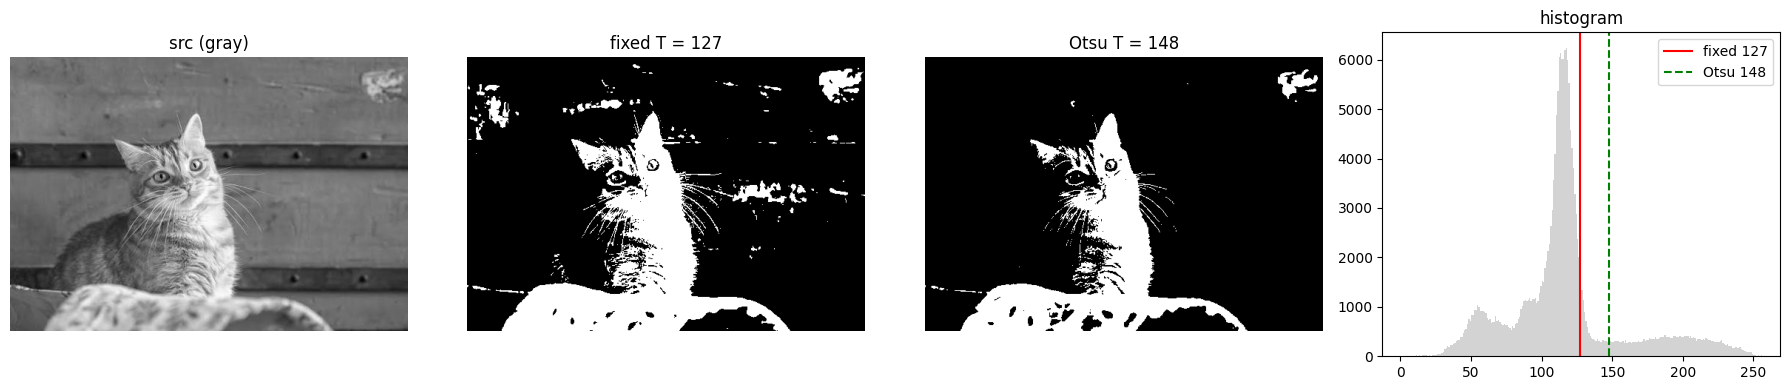

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀灰階圖
src = cv2.imread("images.jpg", cv2.IMREAD_GRAYSCALE)
assert src is not None, "讀不到 images.jpg,請確認路徑"

# 2. 固定閾值 vs Otsu
ret_fixed, dst_fixed = cv2.threshold(src, 127, 255, cv2.THRESH_BINARY)
ret_otsu,  dst_otsu  = cv2.threshold(src, 0,   255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("固定閾值 ret =", ret_fixed)   # 127.0(就是你傳入的值)
print("Otsu     ret =", ret_otsu)    # 演算法算出來的值,不是 0

# 3. 顯示
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].imshow(src, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("src (gray)")

axes[1].imshow(dst_fixed, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"fixed T = {ret_fixed:.0f}")

axes[2].imshow(dst_otsu, cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"Otsu T = {ret_otsu:.0f}")

for ax in axes[:3]:
    ax.axis("off")

# 直方圖 + 兩條閾值線
axes[3].hist(src.ravel(), bins=256, range=(0, 256), color="lightgray")
axes[3].axvline(ret_fixed, color="red",   label=f"fixed {ret_fixed:.0f}")
axes[3].axvline(ret_otsu,  color="green", ls="--", label=f"Otsu {ret_otsu:.0f}")
axes[3].set_title("histogram")
axes[3].legend()

plt.tight_layout()
plt.show()


### THRESH_TRIANGLE

Triangle ret = 135.0
Otsu     ret = 148.0


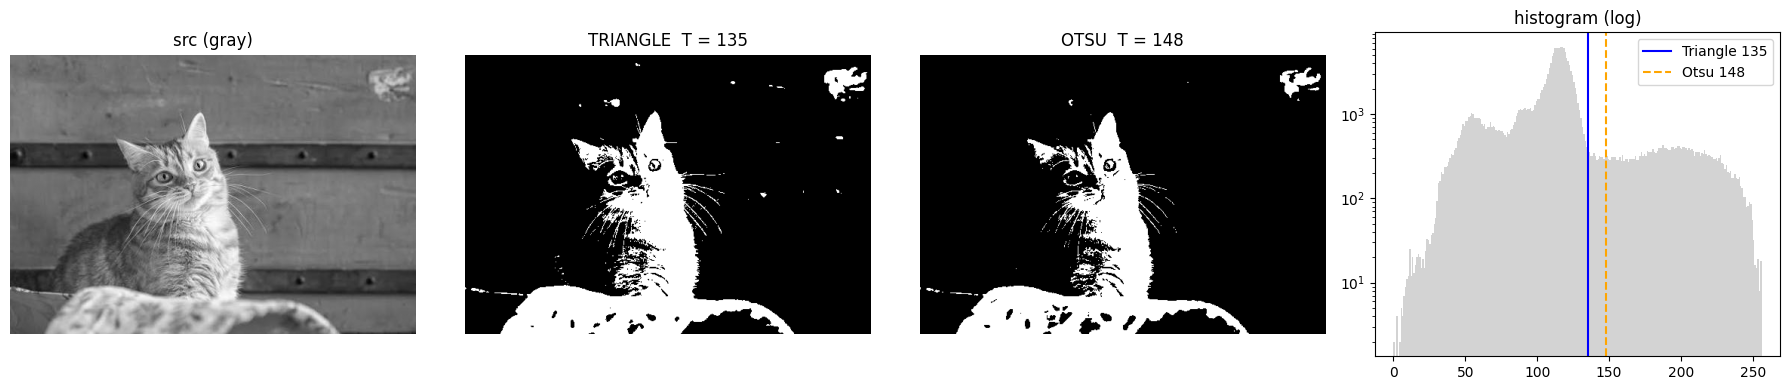

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀灰階圖
src = cv2.imread("images.jpg", cv2.IMREAD_GRAYSCALE)
assert src is not None, "讀不到 images.jpg,請確認路徑"

# 2. Triangle vs Otsu(thresh 傳 0 只是佔位,會被忽略)
ret_tri,  dst_tri  = cv2.threshold(src, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_TRIANGLE)
ret_otsu, dst_otsu = cv2.threshold(src, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Triangle ret =", ret_tri)
print("Otsu     ret =", ret_otsu)

# 3. 顯示
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].imshow(src, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("src (gray)")

axes[1].imshow(dst_tri, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"TRIANGLE  T = {ret_tri:.0f}")

axes[2].imshow(dst_otsu, cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"OTSU  T = {ret_otsu:.0f}")

for ax in axes[:3]:
    ax.axis("off")

# 直方圖(log 縱軸才看得到長尾)+ 兩條閾值線
axes[3].hist(src.ravel(), bins=256, range=(0, 256), color="lightgray", log=True)
axes[3].axvline(ret_tri,  color="blue",   label=f"Triangle {ret_tri:.0f}")
axes[3].axvline(ret_otsu, color="orange", ls="--", label=f"Otsu {ret_otsu:.0f}")
axes[3].set_title("histogram (log)")
axes[3].legend()

plt.tight_layout()
plt.show()


## 4.自適應閾值 Adaptive Thresholding

- threshold adaptive ``局部`` 自我調節設定

cv.adaptiveThreshold(	src, maxValue, adaptiveMethod, thresholdType, blockSize, C[, dst]	) ->	dst




> 自我調整門檻,閾值二值化函數根據圖片一小塊區域的值來計算對應區域的門檻, 閾值，從而得到也許更為合適的圖片。
> * thresh_type ： 門檻, 閾值的計算方法，包含以下2種類型：
>> * cv2.ADAPTIVE_THRESH_MEAN_C : 鄰域`面積的平均值`
>> * cv2.ADAPTIVE_THRESH_GAUSSIAN_C : 高斯窗口的鄰域值的`加權和`
> * Block Size ： 圖片中分塊的大小
> * C ：閾值計算方法中的常數項src−類的對像表示源（輸入）圖像。offset ( thresh - c )

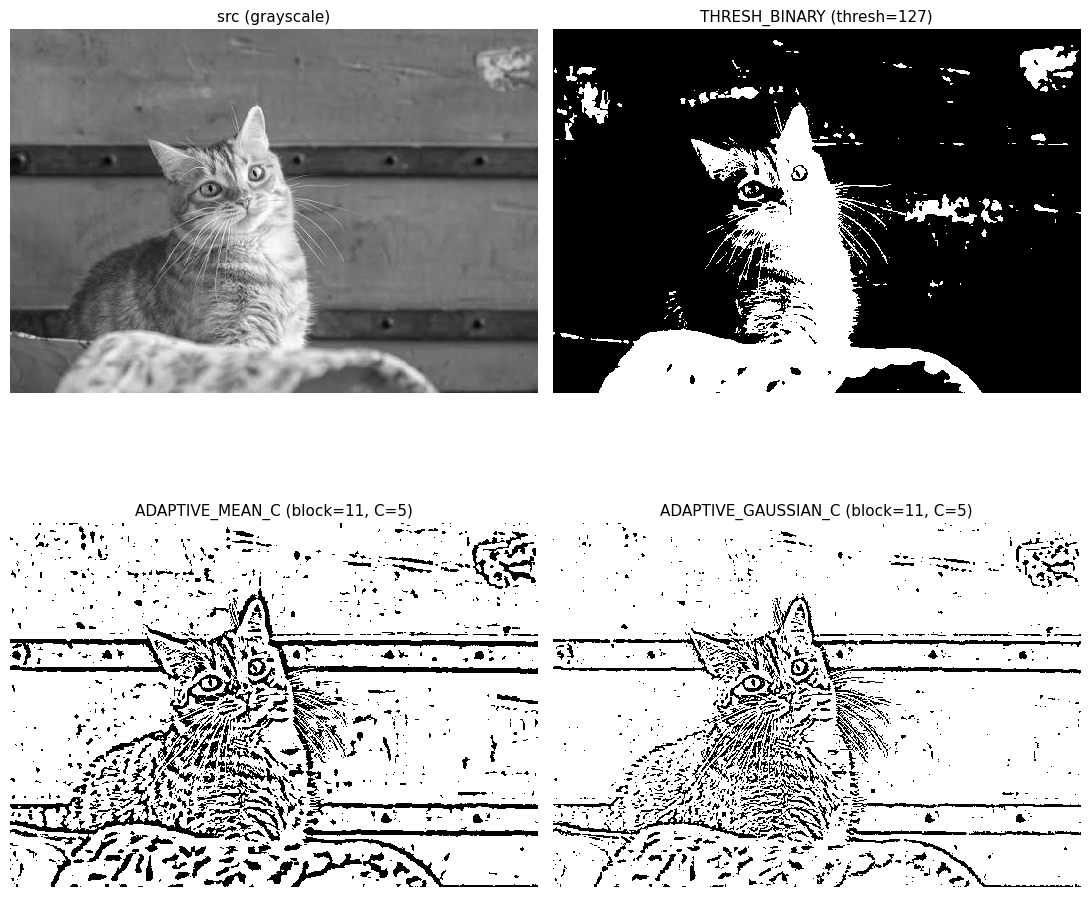

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

src = cv2.imread("images.jpg", cv2.IMREAD_GRAYSCALE)   # 灰階讀取

thresh = 127
maxval = 255

ret, dst = cv2.threshold(src, thresh, maxval, cv2.THRESH_BINARY)

dst_mean  = cv2.adaptiveThreshold(src, maxval,
                                  cv2.ADAPTIVE_THRESH_MEAN_C,
                                  cv2.THRESH_BINARY, 11, 5)
dst_gauss = cv2.adaptiveThreshold(src, maxval,
                                  cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY, 11, 5)

images = [src, dst, dst_mean, dst_gauss]
titles = ["src (grayscale)",
          f"THRESH_BINARY (thresh={thresh})",
          "ADAPTIVE_MEAN_C (block=11, C=5)",
          "ADAPTIVE_GAUSSIAN_C (block=11, C=5)"]

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for ax, img, title in zip(axes.ravel(), images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title, fontsize=11)
    ax.axis("off")

fig.tight_layout()
plt.show()




## 5.多通道範圍閾值 (cv2.inRange)

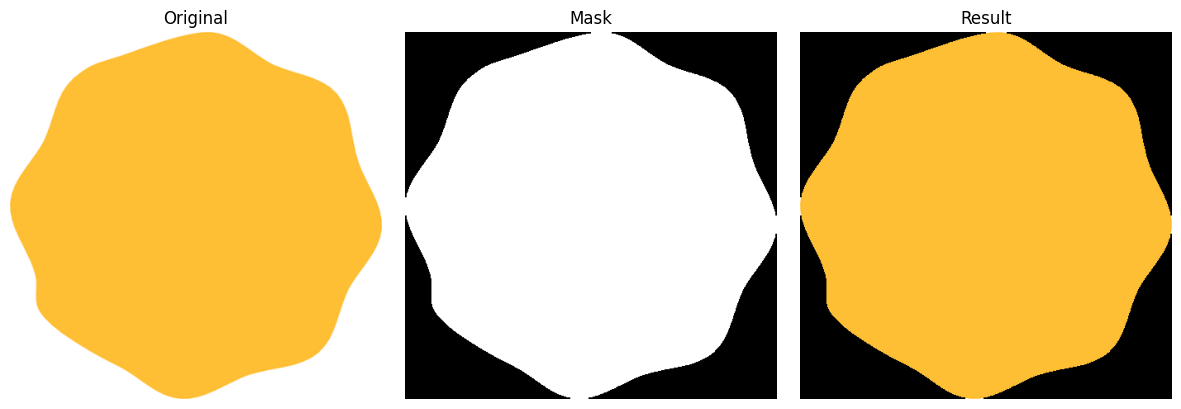

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("color.png")                   # BGR
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

lower = np.array([15, 120, 150], np.uint8)     # H, S, V
upper = np.array([35, 255, 255], np.uint8)

mask = cv2.inRange(hsv, lower, upper)

kernel = np.ones((3, 3), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

result = cv2.bitwise_and(img, img, mask=mask)

# BGR -> RGB（imshow 的期待格式）
img_rgb    = cv2.cvtColor(img,    cv2.COLOR_BGR2RGB)
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_rgb);            axes[0].set_title("Original")
axes[1].imshow(mask, cmap="gray");  axes[1].set_title("Mask")
axes[2].imshow(result_rgb);         axes[2].set_title("Result")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6.統計與正規化運算 (Statistical Operations)

### 尋找極值與位置 (cv2.minMaxLoc)

In [ ]:
import cv2, numpy as np

img  = cv2.imread("irregular2.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

minVal, maxVal, minLoc, maxLoc = cv2.minMaxLoc(gray)
print(f"最暗 {minVal} @ {minLoc}")   # 例如 最暗 88 @ (43, 517)
print(f"最亮 {maxVal} @ {maxLoc}")   # 例如 最亮 255 @ (612, 233)


最暗 66.0 @ (1064, 314)
最亮 255.0 @ (212, 1)


### 全局/局部均值與標準差 (cv2.mean, cv2.meanStdDev)

cv2.mean(gray) = (116.61541698814618, 0.0, 0.0, 0.0)
cv2.mean(bgr)  = (86.93140712832795, 109.67132436196756, 141.50984979809417, 0.0)

gray  mean.shape = (1, 1)
gray  mean = 116.61541698814618  std = 41.45232885236319
bgr   mean.shape = (3, 1)
bgr   mean(B,G,R) = [ 86.93140713 109.67132436 141.5098498 ]
bgr   std (B,G,R) = [46.47704155 44.07480047 38.1018376 ]

mask 內  mean = 161.42  std = 48.93
全圖     mean = 116.62  std = 41.45
numpy ddof=0 std = 48.9270  (與 OpenCV 相同)


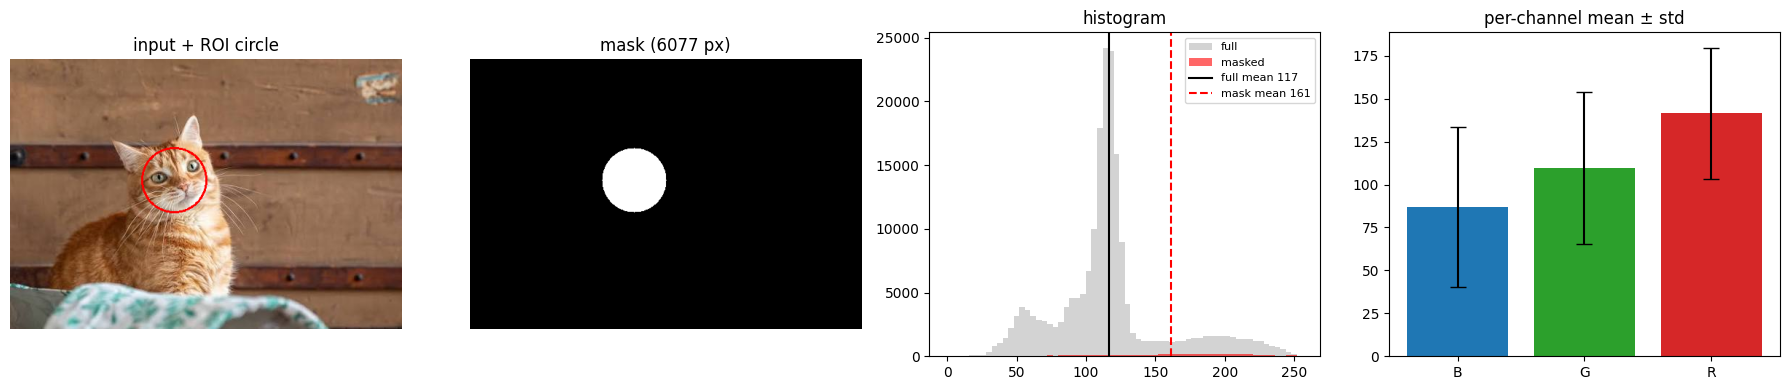

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀圖(灰階 + 彩色)
gray = cv2.imread("images.jpg", cv2.IMREAD_GRAYSCALE)
bgr  = cv2.imread("images.jpg", cv2.IMREAD_COLOR)
assert gray is not None, "讀不到 images.jpg,請確認路徑"
h, w = gray.shape

# 2. cv2.mean:固定回傳 4 個 float
print("cv2.mean(gray) =", cv2.mean(gray))   # (灰階平均, 0, 0, 0)
print("cv2.mean(bgr)  =", cv2.mean(bgr))    # (B, G, R, 0)

# 3. cv2.meanStdDev:回傳 shape = (C, 1) 的 ndarray
mean, std = cv2.meanStdDev(gray)
print("\ngray  mean.shape =", mean.shape)         # (1, 1)
print("gray  mean =", mean[0][0], " std =", std[0][0])

meanC, stdC = cv2.meanStdDev(bgr)
print("bgr   mean.shape =", meanC.shape)          # (3, 1)
print("bgr   mean(B,G,R) =", meanC.ravel())
print("bgr   std (B,G,R) =", stdC.ravel())

# 4. 加 mask:只統計貓臉附近的圓形區域
center = (int(w * 0.42), int(h * 0.45))
radius = int(min(h, w) * 0.12)
mask = np.zeros(gray.shape, np.uint8)
cv2.circle(mask, center, radius, 255, -1)

mM, sM = cv2.meanStdDev(gray, mask=mask)
print(f"\nmask 內  mean = {mM[0][0]:.2f}  std = {sM[0][0]:.2f}")
print(f"全圖     mean = {mean[0][0]:.2f}  std = {std[0][0]:.2f}")

# 5. numpy 驗證:std 是母體標準差(ddof=0)
sel = gray[mask > 0]
print(f"numpy ddof=0 std = {sel.std():.4f}  (與 OpenCV 相同)")

# 6. 顯示
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

shown = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).copy()
cv2.circle(shown, center, radius, (255, 0, 0), 2)
axes[0].imshow(shown)
axes[0].set_title("input + ROI circle")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"mask ({np.count_nonzero(mask)} px)")
axes[1].axis("off")

axes[2].hist(gray.ravel(), bins=64, range=(0, 256), color="lightgray", label="full")
axes[2].hist(sel, bins=64, range=(0, 256), color="red", alpha=0.6, label="masked")
axes[2].axvline(mean[0][0], color="black", label=f"full mean {mean[0][0]:.0f}")
axes[2].axvline(mM[0][0], color="red", ls="--", label=f"mask mean {mM[0][0]:.0f}")
axes[2].set_title("histogram")
axes[2].legend(fontsize=8)

axes[3].bar(["B", "G", "R"], meanC.ravel(), yerr=stdC.ravel(), capsize=6,
            color=["tab:blue", "tab:green", "tab:red"])
axes[3].set_title("per-channel mean ± std")

plt.tight_layout()
plt.show()


### 範圍正規化 (cv2.normalize)

$
\begin{aligned}
\text{MINMAX} &: \quad \mathrm{dst} = \alpha + (\mathrm{src}-m)\frac{\beta-\alpha}{M-m} \\[4pt]
\text{L1} &: \quad \mathrm{dst} = \frac{\alpha}{\sum_i|\mathrm{src}_i|}\,\mathrm{src},
\qquad \textstyle\sum_i|\mathrm{dst}_i| = \alpha \\[4pt]
\text{L2} &: \quad \mathrm{dst} = \frac{\alpha}{\sqrt{\sum_i \mathrm{src}_i^2}}\,\mathrm{src},
\qquad \sqrt{\textstyle\sum_i \mathrm{dst}_i^2} = \alpha \\[4pt]
\text{L2SQR} &: \quad \mathrm{dst} = \frac{\sqrt{\alpha}}{\sqrt{\sum_i \mathrm{src}_i^2}}\,\mathrm{src},
\qquad \textstyle\sum_i \mathrm{dst}_i^2 = \alpha \\[4pt]
\text{INF} &: \quad \mathrm{dst} = \frac{\alpha}{\max_i|\mathrm{src}_i|}\,\mathrm{src},
\qquad \max_i|\mathrm{dst}_i| = \alpha
\end{aligned}
$

影像尺寸      : (2500, 2500, 3) → 灰階 (2500, 2500)
灰階 min / max: 66 / 255   (跨度 189)
灰階 mean/std : 233.23 / 16.77
百分位 1/50/99: [162. 237. 251.]
值為 0 的像素 : 0  (0.000%)

mode                 min         max        Σ|x|   sqrt(Σx²)         Σx²      max|x|       gain   ratio_std
----------------------------------------------------------------------------------------------------------------------
NORM_MINMAX    1.000e+00   2.550e+02   1.411e+09   5.672e+05   3.217e+11   2.550e+02  9.679e-01   3.611e-02
NORM_L1        4.528e-08   1.749e-07   1.000e+00   4.010e-04   1.608e-07   1.749e-07  6.860e-10   1.778e-17
NORM_L2        1.129e-04   4.362e-04   2.494e+03   1.000e+00   1.000e+00   4.362e-04  1.711e-06   3.687e-14
NORM_L2SQR     1.129e-04   4.362e-04   2.494e+03   1.000e+00   1.000e+00   4.362e-04  1.711e-06   3.517e-14
NORM_INF       2.588e-01   1.000e+00   5.716e+06   2.292e+03   5.255e+06   1.000e+00  3.922e-03   3.704e-11

檢查 1：Σ|x| / sqrt(Σx²) / Σx² / max|x| 應各自等於 alpha(=1)
檢查 2：ratio 已排除 s

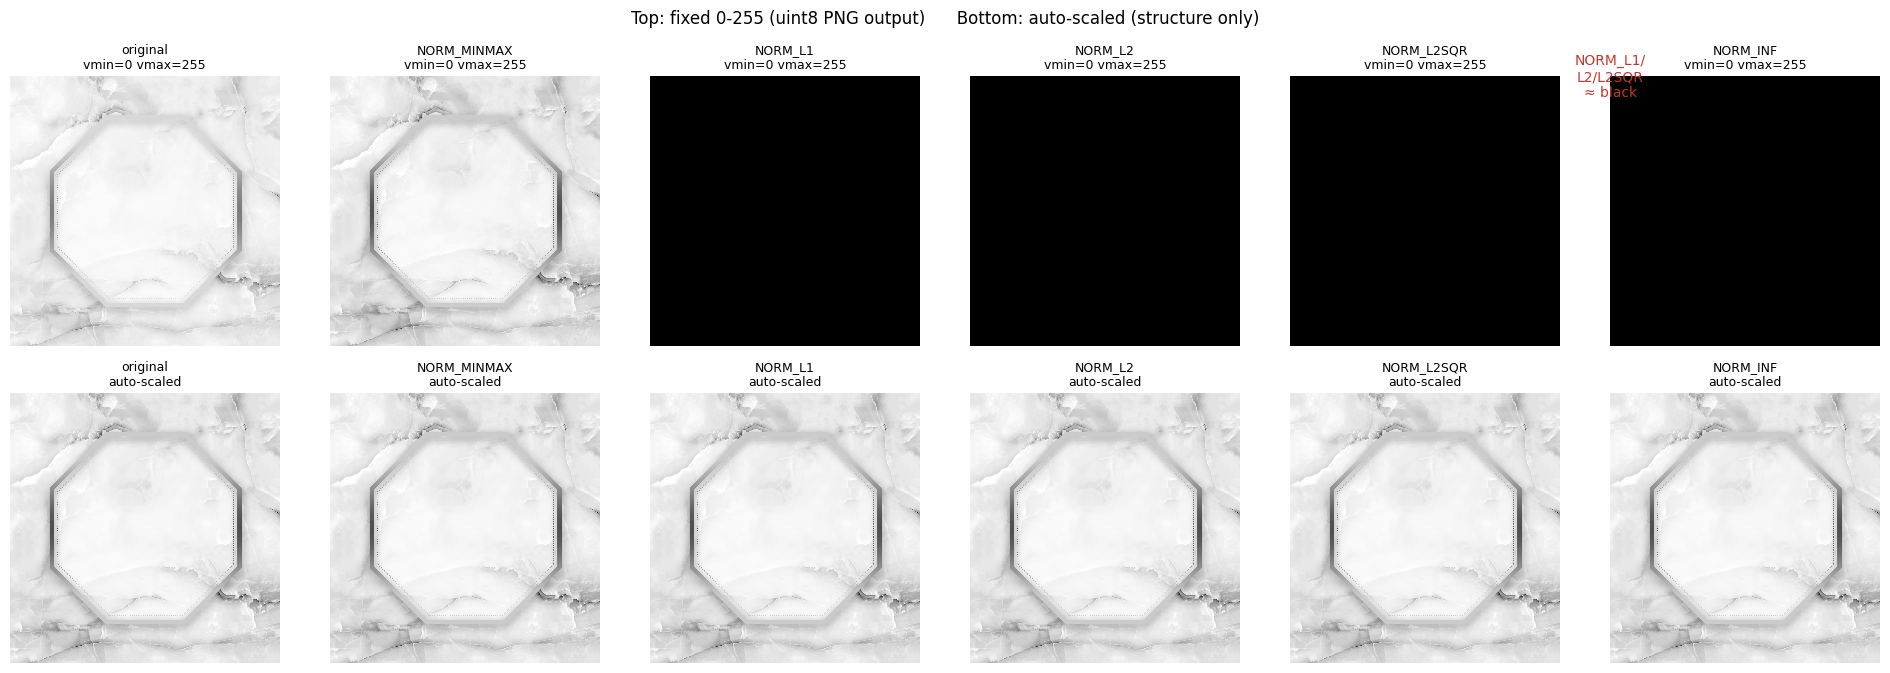

In [ ]:
# -*- coding: utf-8 -*-
"""
cv2.normalize 五種 norm_type 合併範例
OpenCV 5.0.0：NORM_L2SQR 不支援 normalize，需手動實作
"""
import numpy as np
import cv2
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True, linewidth=180)

IMG = "irregular2.png"
bgr = cv2.imread(IMG, cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(f"讀不到 {IMG}；請把 {IMG} 放在程式同一層")

gray8 = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
src   = gray8.astype(np.float32)

n_zero = int((src == 0).sum())
print("影像尺寸      :", bgr.shape, "→ 灰階", gray8.shape)
print("灰階 min / max: %d / %d   (跨度 %d)" % (gray8.min(), gray8.max(),
                                            int(gray8.max()) - int(gray8.min())))
print("灰階 mean/std : %.2f / %.2f" % (gray8.mean(), gray8.std()))
print("百分位 1/50/99:", np.percentile(gray8, [1, 50, 99]).round(1))
print("值為 0 的像素 : %d  (%.3f%%)" % (n_zero, 100 * n_zero / src.size))
print()

ALPHA = 1.0

# ---------- L2SQR 手動：sum(dst^2) = alpha ----------
def normalize_l2sqr(x, alpha=1.0):
    n2 = float(cv2.norm(x, cv2.NORM_L2SQR))          # = sum x^2
    if n2 == 0.0:
        return np.zeros_like(x, dtype=np.float32)
    return (x * (np.sqrt(alpha) / np.sqrt(n2))).astype(np.float32)

MODES = [
    ("NORM_MINMAX", lambda: cv2.normalize(src, None, ALPHA, 255.0,
                                          cv2.NORM_MINMAX, cv2.CV_32F)),
    ("NORM_L1",     lambda: cv2.normalize(src, None, ALPHA, 0,
                                          cv2.NORM_L1,     cv2.CV_32F)),  # beta 無效
    ("NORM_L2",     lambda: cv2.normalize(src, None, ALPHA, 0,
                                          cv2.NORM_L2,     cv2.CV_32F)),  # beta 無效
    ("NORM_L2SQR",  lambda: normalize_l2sqr(src, ALPHA)),                  # 手動
    ("NORM_INF",    lambda: cv2.normalize(src, None, ALPHA, 0,
                                          cv2.NORM_INF,    cv2.CV_32F)),  # beta 無效
]
outs = {name: fn() for name, fn in MODES}

# ---------- 驗證表 ----------
def stats(x):
    x = x.astype(np.float64)
    return dict(min=x.min(), max=x.max(), L1=np.abs(x).sum(),
                L2=np.sqrt((x ** 2).sum()), L2SQR=(x ** 2).sum(),
                INF=np.abs(x).max())

def safe_ratio(dst, s):
    """只在 s != 0 處計算 dst/s，避免 0/0"""
    m = s > 0
    if not m.any():
        return np.array([np.nan]), 0
    return dst[m].astype(np.float64) / s[m].astype(np.float64), int(m.sum())

print(f"{'mode':12s} {'min':>11s} {'max':>11s} {'Σ|x|':>11s} "
      f"{'sqrt(Σx²)':>11s} {'Σx²':>11s} {'max|x|':>11s} {'gain':>10s} {'ratio_std':>11s}")
print("-" * 118)
for name, dst in outs.items():
    s  = stats(dst)
    gain = float(np.mean(dst)) / float(np.mean(src))
    r, nvalid = safe_ratio(dst, src)
    print(f"{name:12s} {s['min']:11.3e} {s['max']:11.3e} {s['L1']:11.3e} "
          f"{s['L2']:11.3e} {s['L2SQR']:11.3e} {s['INF']:11.3e} "
          f"{gain:10.3e} {np.std(r):11.3e}")

print()
print("檢查 1：Σ|x| / sqrt(Σx²) / Σx² / max|x| 應各自等於 alpha(=1)")
print(f"檢查 2：ratio 已排除 src==0 的 {n_zero} 個像素；ratio_std≈0 代表純縮放")
print()

# ---------- 純縮放驗證 ----------
for name in ["NORM_L1", "NORM_L2", "NORM_L2SQR", "NORM_INF"]:
    r, _ = safe_ratio(outs[name], src)
    ok = np.ptp(r) < 1e-6
    print(f"{name:12s} ratio min/max = {r.min():.10e} / {r.max():.10e}  "
          f"ptp={np.ptp(r):.3e}  → {'純縮放 ✔' if ok else '非純縮放 ✘'}")
print()

# ---------- MINMAX 是仿射 ----------
d = outs["NORM_MINMAX"].astype(np.float64)
lo, hi = float(src.min()), float(src.max())
s = (255.0 - ALPHA) / (hi - lo)
manual = ALPHA + (src - lo) * s
print("NORM_MINMAX 手算 vs OpenCV 最大誤差: %.6g" % np.abs(manual - d).max())
print("  scale = (beta-alpha)/(max-min) = %.6f" % s)
print()

# ---------- 視覺化：2 x 6 ----------
items = [("original", src)] + list(outs.items())
fig, axes = plt.subplots(2, 6, figsize=(19, 7))

for col, (name, dst) in enumerate(items):
    axes[0, col].imshow(dst, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[0, col].set_title(f"{name}\nvmin=0 vmax=255", fontsize=9)
    axes[0, col].axis("off")

    axes[1, col].imshow(dst, cmap="gray", interpolation="nearest")
    axes[1, col].set_title(f"{name}\nauto-scaled", fontsize=9)
    axes[1, col].axis("off")

axes[0, 5].text(0.5, 0.5, "NORM_L1/\nL2/L2SQR\n≈ black",
                ha="center", va="center", fontsize=10, color="#c0392b")
plt.suptitle("Top: fixed 0-255 (uint8 PNG output)      "
             "Bottom: auto-scaled (structure only)", fontsize=12)
plt.tight_layout()
plt.savefig("normalize_5modes_2rows.png", dpi=130, bbox_inches="tight")
plt.show()


cv2.normalize 五種 norm_type 的數學定義

##### 0. 符號約定

設影像為 $\mathrm{src} \in \mathbb{R}^{\Omega}$，其中 $\Omega$ 是像素位置集合，$|\Omega| = N$。

對任意位置 $i \in \Omega$，記 $\mathrm{src}_i$ 為該像素值（灰階或多通道皆同，見 §5）。

`cv2.normalize(src, dst, alpha, beta, norm_type, dtype)` 的參數：

| 參數 | 意義 |
|---|---|
| $\alpha$ (`alpha`) | 目標範數，或 `MINMAX` 的下界 |
| $\beta$ (`beta`) | **僅** `NORM_MINMAX` 使用，作為上界 |
| `norm_type` | 決定用哪個泛函數當尺度 |

##### 1. NORM_MINMAX — 仿射映射到 $[\alpha, \beta]$

先定義全域極值：

$
m = \min_{i\in\Omega} \mathrm{src}_i,\qquad M = \max_{i\in\Omega} \mathrm{src}_i
$

則

$
\mathrm{dst}_i = \alpha + \left(\mathrm{src}_i - m\right)\cdot\frac{\beta-\alpha}{M-m},
\qquad M \neq m
$

**性質**：這是**仿射**變換（乘一個常數再加一個常數），不是純縮放。等價寫法：

$
\mathrm{dst}_i = \underbrace{\frac{\beta-\alpha}{M-m}}_{s}\cdot \mathrm{src}_i
+ \underbrace{\left(\alpha - s\,m\right)}_{t}
$

**結果範圍**：$\min_i \mathrm{dst}_i = \min(\alpha,\beta)$，$\max_i \mathrm{dst}_i = \max(\alpha,\beta)$。

> OpenCV 內部會自動取 `smin = MIN(alpha, beta)`、`smax = MAX(alpha, beta)`。
> 因此傳 `alpha=255, beta=0` **不會**產生反相影像，結果與 `alpha=0, beta=255` 相同。

**退化情況** $M = m$（常數影像）：分母為 0，OpenCV 的處理是

$
\mathrm{dst}_i = \alpha \quad \forall i
$

實測：`normalize(全 50 的 (3,4), 0, 255, NORM_MINMAX)` → 全 0；
`normalize(同, 100, 200, NORM_MINMAX)` → 全 100。

##### 2. NORM_L1 — 目標 L1 範數

定義 L1 範數：

$
\|\mathrm{src}\|_1 = \sum_{i\in\Omega} \left|\mathrm{src}_i\right|
$

約束為

$
\sum_{i\in\Omega}\left|\mathrm{dst}_i\right| = \alpha
$

解出

$
\mathrm{dst}_i = \mathrm{src}_i \cdot \frac{\alpha}{\|\mathrm{src}\|_1}
$

**性質**：純縮放，$\mathrm{dst} = k\,\mathrm{src}$，其中 $k = \alpha/\|\mathrm{src}\|_1$。

**典型 $k$ 的量級**：對 $N = 630\,000$、平均灰階 220 的影像，$\|\mathrm{src}\|_1 \approx 1.4\times10^{8}$，
故 $\alpha=1$ 時 $k \approx 7\times10^{-9}$。輸出值全部落在 $10^{-9}$ 級，存成 `uint8` 必然全 0。


##### 3. NORM_L2 — 目標 L2 範數（歐幾里得長度）

$
\|\mathrm{src}\|_2 = \sqrt{\sum_{i\in\Omega}\mathrm{src}_i^{\,2}}
$

約束為

$
\sqrt{\sum_{i\in\Omega}\mathrm{dst}_i^{\,2}} = \alpha
$

解出

$
\mathrm{dst}_i = \mathrm{src}_i\cdot\frac{\alpha}{\|\mathrm{src}\|_2}
$

**性質**：同樣是純縮放，只是除的是「長度」而非「總和」。



##### 4. NORM_L2SQR — 目標平方和

> ⚠️ **OpenCV 5.0.0 的 `cv2.normalize` 不支援此模式**，會拋
> `error: (-5:Bad argument) Unknown/unsupported norm type`。
> `cv2.norm(src, cv2.NORM_L2SQR)` 則可正常使用。定義本身仍然存在：

約束為

$
\sum_{i\in\Omega}\mathrm{dst}_i^{\,2} = \alpha
$

解出

$
\mathrm{dst}_i = \mathrm{src}_i \cdot \frac{\sqrt{\alpha}}{\|\mathrm{src}\|_2}
$

**與 `NORM_L2` 的關係**：把 §3 的式子平方可知，兩者的差別僅在目標值是 $\alpha$ 還是 $\alpha^2$。

$
\|\mathrm{dst}\|_2 = \alpha \;\Longleftrightarrow\; \|\mathrm{dst}\|_2^2 = \alpha^2
$

因此

$
k_{\mathrm{L2}} = \frac{\alpha}{\|\mathrm{src}\|_2},\qquad
k_{\mathrm{L2SQR}} = \frac{\sqrt{\alpha}}{\|\mathrm{src}\|_2}
$

當 $\alpha = 1$ 時兩者**完全相同**；$\alpha \neq 1$ 時相差一個因子 $\sqrt{\alpha}$。
這是實作 L2SQR 最容易寫錯的地方：乘的是 $\sqrt{\alpha}$，不是 $\alpha$。

手動實作：

```python
def normalize_l2sqr(x, alpha=1.0):
    n2 = float(cv2.norm(x, cv2.NORM_L2SQR))        # n2 = sum(x^2) = ||x||_2^2
    if n2 == 0.0:
        return np.zeros_like(x, dtype=np.float32)
    return (x * (np.sqrt(alpha) / np.sqrt(n2))).astype(np.float32)
```


##### 5. NORM_INF — 目標最大絕對值（無窮範數）

$
\|\mathrm{src}\|_\infty = \max_{i\in\Omega}\left|\mathrm{src}_i\right|
$

約束為

$
\max_{i\in\Omega}\left|\mathrm{dst}_i\right| = \alpha
$

解出

$
\mathrm{dst}_i = \mathrm{src}_i\cdot\frac{\alpha}{\left\|\mathrm{src}\right\|_\infty}
$

**性質**：純縮放，且縮放後**最大值恰好等於** $\alpha$。
若令 $\alpha = 255$ 並配合 `uint8`，輸出直接可顯示，不需再拉伸。

